# Deep Learning HW 1
Author: Daniel Bond

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Task Selection
Home Credit Default Risk: [Kaggle Link](https://www.kaggle.com/competitions/home-credit-default-risk)

## EDA and Metric Analysis

In [ ]:
# Datasets from Kaggle
train = pd.read_csv("application_train.csv")
test = pd.read_csv("application_test.csv")
train

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
print(f"Class count: {len(train["TARGET"].unique())}")
nans = {col : train[col].isna().sum() for col in train.columns if train[col].isna().sum() > 0}
print(f"NaN-containing cols: {nans}")
print(f"               count: {len(nans)}")
print(train.dtypes.value_counts())

Class count: 2
NaN-containing cols: {'AMT_ANNUITY': np.int64(12), 'AMT_GOODS_PRICE': np.int64(278), 'NAME_TYPE_SUITE': np.int64(1292), 'OWN_CAR_AGE': np.int64(202929), 'OCCUPATION_TYPE': np.int64(96391), 'CNT_FAM_MEMBERS': np.int64(2), 'EXT_SOURCE_1': np.int64(173378), 'EXT_SOURCE_2': np.int64(660), 'EXT_SOURCE_3': np.int64(60965), 'APARTMENTS_AVG': np.int64(156061), 'BASEMENTAREA_AVG': np.int64(179943), 'YEARS_BEGINEXPLUATATION_AVG': np.int64(150007), 'YEARS_BUILD_AVG': np.int64(204488), 'COMMONAREA_AVG': np.int64(214865), 'ELEVATORS_AVG': np.int64(163891), 'ENTRANCES_AVG': np.int64(154828), 'FLOORSMAX_AVG': np.int64(153020), 'FLOORSMIN_AVG': np.int64(208642), 'LANDAREA_AVG': np.int64(182590), 'LIVINGAPARTMENTS_AVG': np.int64(210199), 'LIVINGAREA_AVG': np.int64(154350), 'NONLIVINGAPARTMENTS_AVG': np.int64(213514), 'NONLIVINGAREA_AVG': np.int64(169682), 'APARTMENTS_MODE': np.int64(156061), 'BASEMENTAREA_MODE': np.int64(179943), 'YEARS_BEGINEXPLUATATION_MODE': np.int64(150007), 'YEARS_B

Train dataset: 307511 rows, 121 columns + target column, contains numeric and categorical values. 67 columns contain NaNs.

In [ ]:
top_share = train.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
near_const = top_share[top_share > 0.99].sort_values(ascending=False)
print(f"{len(near_const)} columns where one value covers >99% of rows:")
near_const.round(4)

18 columns where one value covers >99% of rows:


,0
FLAG_MOBIL,1.0000
FLAG_DOCUMENT_12,1.0000
FLAG_DOCUMENT_10,1.0000
FLAG_DOCUMENT_2,1.0000
FLAG_DOCUMENT_4,0.9999
FLAG_DOCUMENT_7,0.9998
FLAG_DOCUMENT_17,0.9997
FLAG_DOCUMENT_21,0.9997
FLAG_DOCUMENT_20,0.9995
FLAG_DOCUMENT_19,0.9994


In [ ]:
rows = []
for c in near_const.index:
    top = train[c].mode()[0]
    minority = train[c] != top
    rows.append([c, minority.sum(),
                 train.loc[minority, "TARGET"].mean(),
                 train.loc[~minority, "TARGET"].mean()])
pd.DataFrame(rows, columns=["feature", "n_minority", "default_rate_minority",
                            "default_rate_majority"]).round(4)

,feature,n_minority,default_rate_minority,default_rate_majority
0,FLAG_MOBIL,1,0.0000,0.0807
1,FLAG_DOCUMENT_12,2,0.0000,0.0807
2,FLAG_DOCUMENT_10,7,0.0000,0.0807
3,FLAG_DOCUMENT_2,13,0.3077,0.0807
4,FLAG_DOCUMENT_4,25,0.0000,0.0807
5,FLAG_DOCUMENT_7,59,0.0508,0.0807
6,FLAG_DOCUMENT_17,82,0.0244,0.0807
7,FLAG_DOCUMENT_21,103,0.1359,0.0807
8,FLAG_DOCUMENT_20,156,0.0833,0.0807
9,FLAG_DOCUMENT_19,183,0.0656,0.0807


18 columns with mostly same values. Dropping some columns from here would be ok, as they won't have much impact during training.

Some are worth keeping: FLAG_DOCUMENT_15, FLAG_DOCUMENT_14, FLAG_DOCUMENT_13, FLAG_DOCUMENT_18, FLAG_DOCUMENT_16. All of them have some useful data despite having >99% of rows with one value, showing significant difference between minority and majority default rates

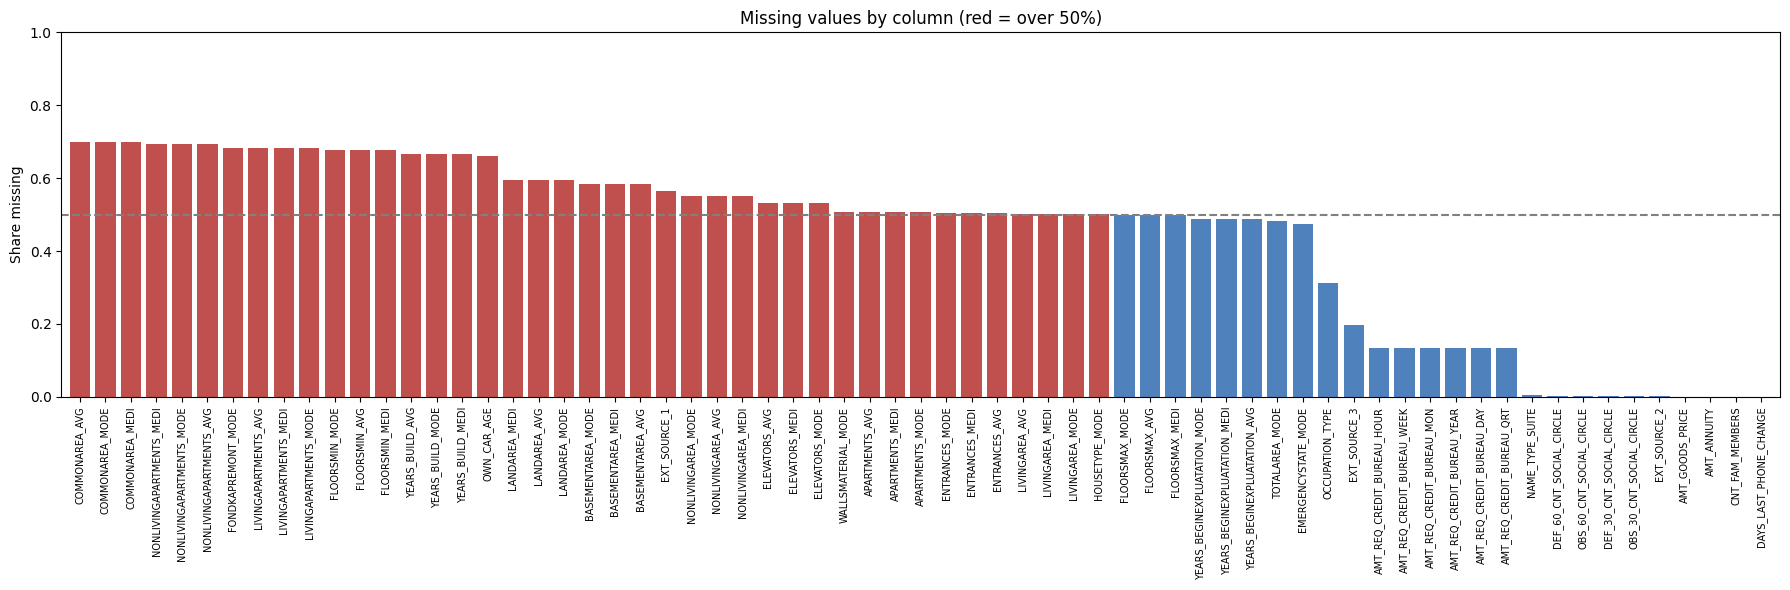

In [ ]:
miss = train.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(18, 6))
ax.bar(miss.index, miss.values, color=["#c0504d" if v > 0.5 else "#4f81bd" for v in miss])
ax.axhline(0.5, ls="--", c="grey")
ax.set_ylabel("Share missing")
ax.set_ylim(0, 1)
ax.set_title("Missing values by column (red = over 50%)")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.margins(x=0.005)
plt.tight_layout()
plt.show()

In [ ]:
print(train[["COMMONAREA_AVG", "COMMONAREA_MODE", "COMMONAREA_MEDI"]].corr().round(3))

                 COMMONAREA_AVG  COMMONAREA_MODE  COMMONAREA_MEDI
COMMONAREA_AVG            1.000            0.977            0.996
COMMONAREA_MODE           0.977            1.000            0.980
COMMONAREA_MEDI           0.996            0.980            1.000


Most of the high-missing columns are of AVG/MODE/MEDI class, and are highly correlated between themselves. This way, only one of the classes is worth keeping - I'll keep only MODE, as there are some columns that don't have AVG/MEDI alternatives.


In [ ]:
# Anomalies
anom = train["DAYS_EMPLOYED"] == 365243 # probably not a real value, placeholder used for unemployed (Pensioner/Unemployed)
print(f"DAYS_EMPLOYED == 365243: {anom.sum()} rows ({anom.mean():.1%})") # 18%, clipping will not help - replacing with nan is a better marker
print(train.loc[anom, "NAME_INCOME_TYPE"].value_counts())

money = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
desc = train[money].describe(percentiles=[.01, .5, .99]).T
desc["max/p99"] = desc["max"] / desc["99%"]
desc.round(0)

DAYS_EMPLOYED == 365243: 55374 rows (18.0%)
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


,count,mean,std,min,1%,50%,99%,max,max/p99
AMT_INCOME_TOTAL,307511.0,168798.0,237123.0,25650.0,45000.0,147150.0,472500.0,117000000.0,248.0
AMT_CREDIT,307511.0,599026.0,402491.0,45000.0,76410.0,513531.0,1854000.0,4050000.0,2.0
AMT_ANNUITY,307499.0,27109.0,14494.0,1616.0,6183.0,24903.0,70006.0,258026.0,4.0
AMT_GOODS_PRICE,307233.0,538396.0,369446.0,40500.0,67500.0,450000.0,1800000.0,4050000.0,2.0


Big difference between 99% and max for AMT_INCOME_TOTAL here, needs clipping

In [ ]:
# Merging rare income classes into Other
main = ["Working", "Commercial associate", "Pensioner", "State servant"]
cap = train["AMT_INCOME_TOTAL"].quantile(0.999)
for d in (train, test):
  d["AMT_INCOME_TOTAL"] = d["AMT_INCOME_TOTAL"].clip(upper=cap)
  d["DAYS_EMPLOYED"] = d["DAYS_EMPLOYED"].replace(365243, np.nan)
  d["NAME_INCOME_TYPE"] = d["NAME_INCOME_TYPE"].where(d["NAME_INCOME_TYPE"].isin(main), "Other")

print(train["NAME_INCOME_TYPE"].value_counts())

NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Other                       55
Name: count, dtype: int64


In [ ]:
# Dropping columns decided in previous cells
drop_cols = [c for c in train.columns if c.endswith(("_AVG", "_MEDI"))] + ["FLAG_MOBIL",
    "FLAG_DOCUMENT_2","FLAG_DOCUMENT_4","FLAG_DOCUMENT_7","FLAG_DOCUMENT_10","FLAG_DOCUMENT_12",
    "FLAG_DOCUMENT_17","FLAG_CONT_MOBILE","FLAG_DOCUMENT_9","FLAG_DOCUMENT_11","FLAG_DOCUMENT_19",
    "FLAG_DOCUMENT_20","FLAG_DOCUMENT_21",
] + ["SK_ID_CURR"]
test_ids = test["SK_ID_CURR"].copy()
train.drop(columns=drop_cols, inplace=True)
test.drop(columns=drop_cols, inplace=True)

In [ ]:
num = train.select_dtypes("number").drop(columns=["TARGET"])
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)

print("Most correlated feature pairs:")
pairs[pairs > 0.8].round(3)

Most correlated feature pairs:


OBS_30_CNT_SOCIAL_CIRCLE    OBS_60_CNT_SOCIAL_CIRCLE       0.998
AMT_CREDIT                  AMT_GOODS_PRICE                0.987
REGION_RATING_CLIENT        REGION_RATING_CLIENT_W_CITY    0.951
APARTMENTS_MODE             LIVINGAPARTMENTS_MODE          0.938
                            LIVINGAREA_MODE                0.910
LIVINGAREA_MODE             TOTALAREA_MODE                 0.899
CNT_CHILDREN                CNT_FAM_MEMBERS                0.879
LIVINGAPARTMENTS_MODE       LIVINGAREA_MODE                0.878
APARTMENTS_MODE             TOTALAREA_MODE                 0.864
REG_REGION_NOT_WORK_REGION  LIVE_REGION_NOT_WORK_REGION    0.861
DEF_30_CNT_SOCIAL_CIRCLE    DEF_60_CNT_SOCIAL_CIRCLE       0.861
ELEVATORS_MODE              LIVINGAREA_MODE                0.856
LIVINGAPARTMENTS_MODE       TOTALAREA_MODE                 0.834
APARTMENTS_MODE             ELEVATORS_MODE                 0.826
REG_CITY_NOT_WORK_CITY      LIVE_CITY_NOT_WORK_CITY        0.826
ELEVATORS_MODE              TOTALAREA_MODE                 0.821
                            LIVINGAPARTMENTS_MODE          0.808
dtype: float64

In [ ]:
# Columns, that have correlation and carry similar data (like REGION_RATING_CLIENT_W_CITY and REGION_RATING - no need for both here)
drop_cols = ["OBS_30_CNT_SOCIAL_CIRCLE", "REGION_RATING_CLIENT_W_CITY"]
train.drop(columns=drop_cols, inplace=True)
test.drop(columns=drop_cols, inplace=True)

In [ ]:
print(f"Class balance check: {(train["TARGET"].sum()/train["TARGET"].count())*100:.2f}% of TARGET are 1")

Class balance check: 8.07% of TARGET are 1


Result: `Class balance check: 8.07` - only 8% of values are of positive class, clear disbalance.

### Metric Analysis
The chosen metric is ROC-AUC.
Pros:
- Insensitive to class balance, and with 8-to-92 ratio is better than accuracy.
- Doesn't depend on threshold selection
- Can show "ranking" of default risk scores, instead of clear classification (good for selecting some % of riskiest clients)

Cons:
- Can look good, while precision is poor (On inbalanced classes many false positives won't impact ROC-AUC as much as PR-AUC, leading to seemingly good evaluations)
- Ignores actual numbers - [0.53, 0.56, 0.57] and [0.1, 0.2, 0.7] would give the same score, only measuring the order and not the scale

Complementary: PR-AUC (focusing on minority class predictions), Log loss (closing the gap of checking actual probabilites, ignored by ROC-AUC)

Alternative: Recall - checking how many of actual defaults were caught by prediction. Pros - false-negative is more expensive for the bank than false-positive, so catching most of the defaults is more important than marking all non-defaults. Cons - needs some limits to also reduce false-positives, like ranking clients by scores and rejecting only the riskiest 10%, and this threshold can also influence preformance. Considering the negative side, best to use "fixed rejection amount recall" with ROC-AUC as complementary to mitigate the risks of using only recall and check the overall quality

Now, it is time to handle NaNs and string columns

In [ ]:
# All string columns are converted into embeddings
cat_cols = train.select_dtypes("object").columns.tolist()

vocab = {}
for c in cat_cols:
    cats = sorted(train[c].fillna("Missing").unique())
    vocab[c] = {v: i + 1 for i, v in enumerate(cats)}
    for d in (train, test):
        d[c] = d[c].fillna("Missing").map(vocab[c]).fillna(0).astype("int64")

cardinalities = [len(vocab[c]) + 1 for c in cat_cols]
emb_dims = [min(10, (n + 1) // 2) for n in cardinalities]

print(dict(zip(cat_cols, cardinalities)))

{'NAME_CONTRACT_TYPE': 3, 'CODE_GENDER': 4, 'FLAG_OWN_CAR': 3, 'FLAG_OWN_REALTY': 3, 'NAME_TYPE_SUITE': 9, 'NAME_INCOME_TYPE': 6, 'NAME_EDUCATION_TYPE': 6, 'NAME_FAMILY_STATUS': 7, 'NAME_HOUSING_TYPE': 7, 'OCCUPATION_TYPE': 20, 'WEEKDAY_APPR_PROCESS_START': 8, 'ORGANIZATION_TYPE': 59, 'FONDKAPREMONT_MODE': 6, 'HOUSETYPE_MODE': 5, 'WALLSMATERIAL_MODE': 9, 'EMERGENCYSTATE_MODE': 4}


The categoricals are done, now numeric NaNs

In [ ]:
TARGET = "TARGET"
MIN_MISSING_FRAC = 0.01

num_cols = train.select_dtypes(include="number").columns.drop([TARGET] + cat_cols, errors="ignore")
missing_frac = train[num_cols].isna().mean()
flag_cols = missing_frac[missing_frac >= MIN_MISSING_FRAC].index.tolist()

def add_missing_flags(df):
    flags = df[flag_cols].isna().astype("int8").add_suffix("_missing")
    flags["n_missing_num"] = df[num_cols].isna().sum(axis=1).astype("int8")
    return pd.concat([df, flags], axis=1)

train_flagged = add_missing_flags(train)
test_flagged = add_missing_flags(test)

n_skipped = missing_frac.between(0, MIN_MISSING_FRAC, inclusive="neither").sum()
test_only = [c for c in num_cols if train[c].notna().all() and test[c].isna().any()]

print(f"Numerical columns:                 {len(num_cols)}")
print(f"  with missing values in train:    {(missing_frac > 0).sum()}")
print(f"  flags created:                   {len(flag_cols)}")
print(f"  skipped (< {MIN_MISSING_FRAC:.0%} missing):          {n_skipped}")
if test_only:
    print(f"Warning: missing only in test (no flag): {test_only}")
print(f"\ntrain: {train.shape} -> {train_flagged.shape}")
print(f"test:  {test.shape} -> {test_flagged.shape}")

Numerical columns:                 61
  with missing values in train:    33
  flags created:                   25
  skipped (< 1% missing):          8

train: (307511, 78) -> (307511, 104)
test:  (48744, 77) -> (48744, 103)


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_list = list(num_cols)

imputer = SimpleImputer(strategy="median")
train_flagged[num_list] = imputer.fit_transform(train_flagged[num_list])
test_flagged[num_list] = imputer.transform(test_flagged[num_list])

scale_cols = num_list + (["n_missing_num"] if "n_missing_num" in train_flagged else [])
scaler = StandardScaler()
train_flagged[scale_cols] = scaler.fit_transform(train_flagged[scale_cols])
test_flagged[scale_cols] = scaler.transform(test_flagged[scale_cols])

assert not train_flagged[num_list].isna().any().any()
assert not test_flagged[num_list].isna().any().any()

Final train_x/_y ready for passing into a model:

In [ ]:
train_x, train_y = train_flagged.drop("TARGET", axis=1), train_flagged["TARGET"]

### The end of EDA/Metric chapter of this task
I will split the work into multiple .ipynb files, so that it is easier to follow.

In [ ]:
# Exporting trainable datasets + metadata for embeddings
train_x.to_csv("train_x_bronze.csv.gz", index=False)
train_y.to_csv("train_y_bronze.csv.gz", index=False)
test_flagged.assign(SK_ID_CURR=test_ids.values).to_csv("test_bronze.csv.gz", index=False)
import json
with open("meta.json", "w") as f:
    json.dump({"cat_cols": cat_cols, "cardinalities": cardinalities,
               "emb_dims": emb_dims}, f)